# IsoVita quick start

Learn one interpretable isoform balance per gene, then test discrete and continuous age associations. This example uses **synthetic data and 99 permutations**, solely to demonstrate the API. The minimum attainable p-value is 0.01, too coarse for many production BH analyses. No significant discoveries are required for this notebook to work.

From the extracted repository, install `python -m pip install -e ".[notebook]"`, open this notebook, and select that environment's Python kernel. No external datasets or helper scripts are needed.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from isovita import (
    IsoVitaConfig, PermutationInferenceConfig,
    prepare_isovita_inputs_from_expression, run_isovita_pipeline,
    compute_balance_feature, make_effective_isoform_composition,
)

## 1. Generate transcript-level data
The three genes illustrate a step, a smooth trajectory, and an age-null control. Correlated noise is added before compositional normalization.

In [2]:
rng = np.random.default_rng(2026)
ages = np.linspace(1, 80, 48)
samples = [f"S{i:03d}" for i in range(len(ages))]
metadata = pd.DataFrame({"sample_id": samples, "age": ages})
expression_rows, mapping_rows = [], []
# Latent transcript trajectories -> softmax fractions -> positive gene totals.
# This follows the supplied simulator's model; it does not plant an IsoVita balance.
for gene, kind, k in [("STEP", "step", 2), ("SMOOTH", "sigmoid", 4), ("NULL", "null", 3)]:
    shape = (np.where(ages < 40, -1.0, 1.0) if kind == "step"
             else np.tanh((ages - 42) / 16) if kind == "sigmoid"
             else np.zeros(len(ages)))
    shape = shape - shape.mean()
    scale = np.max(np.abs(shape))
    if scale > 0:
        shape = shape / scale
    loadings = np.linspace(1.0, -0.9, k)
    baseline = rng.normal(0, 0.15, k)
    covariance = 0.25**2 * (0.9 * np.eye(k) + 0.1 * np.ones((k, k)))
    noise = rng.multivariate_normal(np.zeros(k), covariance, size=len(ages))
    latent = baseline + 0.7 * shape[:, None] * loadings + noise
    exp_latent = np.exp(latent - latent.max(axis=1, keepdims=True))
    fraction = exp_latent / exp_latent.sum(axis=1, keepdims=True)
    abundance = fraction * rng.lognormal(np.log(50), 0.15, len(ages))[:, None]
    for j in range(k):
        tx = f"{gene}_TX{j + 1}"
        expression_rows.append({"tx_id": tx, **dict(zip(samples, abundance[:, j]))})
        mapping_rows.append({"tx_id": tx, "gene_id": gene})
expression = pd.DataFrame(expression_rows)
tx2gene = pd.DataFrame(mapping_rows)
print(expression.shape, metadata.shape)
expression.iloc[:, :6]

(9, 49) (48, 2)
Out[0]: 
        tx_id       S000       S001       S002       S003       S004
0    STEP_TX1   5.294795   8.541327   6.330459   9.775716   9.225531
1    STEP_TX2  37.335120  34.192789  30.948864  40.012154  48.408056
2  SMOOTH_TX1   7.103568   5.028164   8.247865   4.745963  10.197231
3  SMOOTH_TX2   8.373575   6.248237  15.379805   6.663422  14.100045
4  SMOOTH_TX3  15.132146  17.959875   8.208452   7.685987  15.003916
5  SMOOTH_TX4  22.839612  24.088541  15.764524  29.229642  17.347247
6    NULL_TX1  25.247396  22.881822  18.929237  26.415193  23.213859
7    NULL_TX2  10.715211  13.835456  19.991881   8.695824   7.772226
8    NULL_TX3  14.200873  12.753952  12.932423  11.637195   9.842274


## 2. Prepare canonical inputs
The adapter aligns sample columns to metadata, joins transcript-to-gene mapping, and validates nonnegative finite expression. Postnatal filtering is enabled by default.

In [3]:
prepared = prepare_isovita_inputs_from_expression(
    expression=expression, metadata=metadata, tx2gene=tx2gene,
    metadata_sample_col="sample_id", age_col="age",
)
display(prepared.summary)
assert prepared.tpm.columns[2:].tolist() == prepared.metadata.sample_id.tolist()

,metric,value
0,retained_samples,48.0
1,retained_transcripts,9.0
2,retained_genes,3.0
3,age_min,1.0
4,age_max,80.0
5,n_negative_age,0.0


## 3. Run both branches
Real IsoPlex selects effective isoforms. IsoVita relearns multi-isoform balances under each age permutation; the unique two-isoform contrast needs no reselection for sign-invariant test statistics.

In [4]:
config = IsoVitaConfig(
    inference=PermutationInferenceConfig(n_permutations=99, random_seed=7, batch_size=32)
)
result = run_isovita_pipeline(
    tpm=prepared.tpm, metadata=prepared.metadata,
    branches=("discrete", "continuous"), config=config, n_jobs=1,
)
display(result.gene_routes[["gene_id", "n_effective", "route"]])

,gene_id,n_effective,route
0,NULL,3,balance_ge2
1,SMOOTH,4,balance_ge2
2,STEP,2,balance_ge2


## 4. Inspect inference
`p_value` is the selection-aware permutation p-value. `q_value` is BH-adjusted within each branch. `analytic_p_value` in the continuous table is diagnostic and does not account for feature selection. The final union is not a third FDR-controlled family.

In [5]:
display(result.discrete_trajectory_results[["gene_id", "max_f_stat", "best_change_age", "p_value", "q_value", "fdr_significant"]])
display(result.continuous_trajectory_results[["gene_id", "f_stat", "p_value", "q_value", "fdr_significant"]])
display(result.final_features)
assert result.balance_summary.status.eq("ok").all()

,gene_id,max_f_stat,best_change_age,p_value,q_value,fdr_significant
0,STEP,916.663922,40.500000,0.01,0.015,True
1,SMOOTH,158.173703,47.223404,0.01,0.015,True
2,NULL,1.199657,58.989362,0.92,0.920,False


,gene_id,f_stat,p_value,q_value,fdr_significant
0,STEP,66.501275,0.01,0.015,True
1,SMOOTH,116.141615,0.01,0.015,True
2,NULL,0.174762,0.97,0.970,False


,rank_gene,gene_id,status,n_effective,n_samples,group_A,group_B,unused_isoforms,n_group_A,n_group_B,n_unused,n_used,cosine_similarity,best_cosine_similarity,cosine_gap_from_best,n_near_optimal,pc1_explained_variance_ratio,feature_robust_amplitude,feature_sd,balance_method,discrete_p_value,discrete_q_value,discrete_fdr_significant,discrete_max_f_stat,discrete_step_r_squared,discrete_step_effect,discrete_abs_step_effect,discrete_change_age,discrete_left_mean,discrete_right_mean,discrete_n_left,discrete_n_right,discrete_n_candidate_cuts,continuous_p_value,continuous_q_value,continuous_fdr_significant,continuous_f_stat,continuous_r_squared,continuous_fitted_robust_amp,continuous_pearson_r,continuous_spearman_r,continuous_abs_pearson_r,score_predictive_hybrid,n_detection_branches,trajectory_signature,min_branch_q_value
0,1,SMOOTH,ok,4,48,SMOOTH_TX4,SMOOTH_TX1,SMOOTH_TX2|SMOOTH_TX3,1,1,2,2,0.952462,0.952462,-1.110223e-16,NaN,0.994559,3.092721,1.059983,CLR_smooth_PC1_sparse_balance,0.01,0.015,True,158.173703,0.774702,-1.872586,1.872586,47.223404,0.638324,-1.234262,28,20,29,0.01,0.015,True,116.141615,0.887877,2.563215,-0.919110,-0.903604,0.919110,2.355877,2,discrete+continuous,0.015
1,2,STEP,ok,2,48,STEP_TX1,STEP_TX2,,1,1,0,2,1.000000,1.000000,0.000000e+00,1.0,1.000000,3.562982,1.480823,CLR_smooth_PC1_sparse_balance,0.01,0.015,True,916.663922,0.952216,2.859756,2.859756,40.500000,-1.645639,1.214117,24,24,29,0.01,0.015,True,66.501275,0.819305,3.485248,0.836939,0.746418,0.836939,2.916941,2,discrete+continuous,0.015


## 5. Interpret a balance
A positive feature means the geometric mean composition of group A exceeds that of group B. The feature is a natural-log ratio, without an ILR normalization factor. A/B orientation follows the dominant smoothed CLR loading; it is not forced to increase with age.

In [6]:
display(result.balance_summary[["gene_id", "group_A", "group_B", "unused_isoforms", "n_used", "cosine_similarity"]])
gene = "SMOOTH"
route = result.gene_routes.set_index("gene_id").loc[gene]
composition = make_effective_isoform_composition(
    gene, result.tpm, route.effective_isoforms,
    prepared.metadata.sample_id.tolist(), result.metadata,
    pseudocount=config.balance.clr_pseudocount, min_samples=config.balance.min_samples,
)
assignment = (result.balance_loadings.query("gene_id == @gene")
              .set_index("transcript_id").loc[composition["isoforms"], "balance_assignment"].to_numpy())
recomputed = compute_balance_feature(composition["composition"], assignment)
np.testing.assert_allclose(recomputed, result.balance_feature_matrix.loc[gene])

,gene_id,group_A,group_B,unused_isoforms,n_used,cosine_similarity
0,NULL,NULL_TX2,NULL_TX1|NULL_TX3,,3,0.999634
1,SMOOTH,SMOOTH_TX4,SMOOTH_TX1,SMOOTH_TX2|SMOOTH_TX3,2,0.952462
2,STEP,STEP_TX1,STEP_TX2,,2,1.000000


## 6. Plot the learned features
Raw dots show the observed feature, with the estimated discrete cut marked when testable. A cut is a descriptive estimate; significance comes from the permutation results.

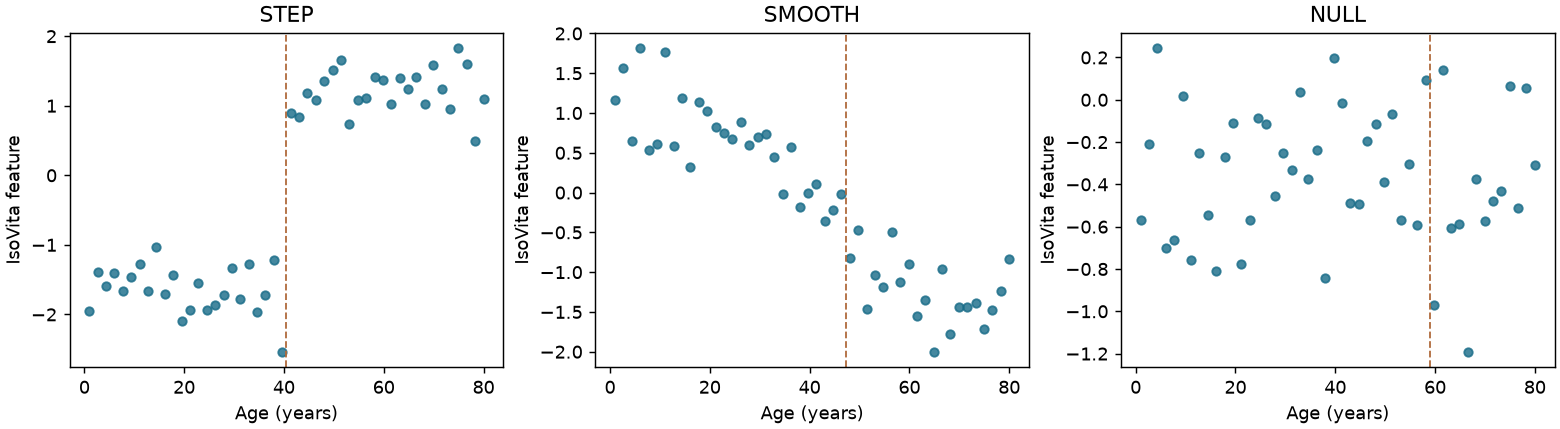

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.3), constrained_layout=True)
for ax, gene in zip(axes, ["STEP", "SMOOTH", "NULL"]):
    values = result.balance_feature_matrix.loc[gene]
    age = result.metadata.loc[values.index, "age"]
    ax.scatter(age, values, s=22, color="#176B87", alpha=0.8)
    row = result.discrete_trajectory_results.set_index("gene_id").loc[gene]
    if row.tested:
        ax.axvline(row.best_change_age, color="#B06A3B", linestyle="--", linewidth=1)
    ax.set(title=gene, xlabel="Age (years)", ylabel="IsoVita feature")
plt.show()

For real data, select a permutation count suitable for the tested family size and desired tail resolution (5,000 is a useful starting point, not a guarantee). Review the README limitations, especially exchangeability and the absence of covariate adjustment. To export tables, use `save_isovita_pipeline_outputs(result, "isovita_results")`.

## 7. Optional tests within user-defined windows

The original `localized` flag enables both existing detectors within specified intervals. The balance is still learned globally; every age permutation relearns that global feature before testing its window samples. Windowed results do not change `final_features`. BH correction is separate for the windowed discrete and continuous families across all gene × window pairs.

Below, `[1, 40)` and `[40, 80]` each have 24 samples. The last upper edge is included. Choose windows in advance; selecting them after inspecting results is not accounted for.

In [8]:
from dataclasses import replace
from isovita import WindowConfig

window_config = replace(config, windows=WindowConfig(edges=(1, 40, 80)))
window_result = run_isovita_pipeline(
    tpm=prepared.tpm, metadata=prepared.metadata,
    branches=("discrete", "continuous", "localized"), config=window_config,
)
for table in (window_result.localized_discrete_results,
              window_result.localized_continuous_results):
    display(table[["gene_id", "window", "n", "tested", "p_value", "q_value", "fdr_significant"]])
    assert len(table) == 6
pd.testing.assert_frame_equal(window_result.final_features, result.final_features)
# Windowed-only execution is also available with branches=("localized",).

/workspace/scratch/139ff19dbde4/revision/isovita/src/isovita/permutation.py:821: RuntimeWarning: Windowed discrete permutation resolution may be coarse for BH: minimum p=0.01, first BH threshold=0.00833. Increase inference.n_permutations when precise tail resolution is required.
  out["localized_discrete"] = _finalize_discrete_table(
/workspace/scratch/139ff19dbde4/revision/isovita/src/isovita/permutation.py:827: RuntimeWarning: Windowed continuous permutation resolution may be coarse for BH: minimum p=0.01, first BH threshold=0.00833. Increase inference.n_permutations when precise tail resolution is required.
  out["localized_continuous"] = _finalize_continuous_table(


,gene_id,window,n,tested,p_value,q_value,fdr_significant
0,SMOOTH,40-80,24,True,0.01,0.030,True
1,SMOOTH,1-40,24,True,0.01,0.030,True
2,STEP,1-40,24,True,0.16,0.320,False
3,NULL,1-40,24,True,0.40,0.600,False
4,NULL,40-80,24,True,0.52,0.624,False
5,STEP,40-80,24,True,0.77,0.770,False


,gene_id,window,n,tested,p_value,q_value,fdr_significant
0,SMOOTH,40-80,24,True,0.01,0.030,True
1,SMOOTH,1-40,24,True,0.01,0.030,True
2,NULL,40-80,24,True,0.53,0.696,False
3,STEP,1-40,24,True,0.56,0.696,False
4,STEP,40-80,24,True,0.58,0.696,False
5,NULL,1-40,24,True,0.87,0.870,False
